# E3.3 Temporal Error Analysis

Compute all monthly errors from the unchanged saved validation predictions, after checking indices, labels and aggregate metrics. No target-derived feature or prediction correction is constructed.

One identical E3.3 refit provides training gain/split importance. Compare its predictions against the saved model output, then inspect the effect of changing only month_index within the validation range and clipping it to the training maximum. These isolated sensitivity inputs do not replace official predictions or enter reported monthly errors. Training importance is not out-of-sample or causal importance. Mean underprediction alone does not identify concept drift.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'src').is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / 'src').is_dir()
sys.path.insert(0, str(PROJECT_ROOT))
from experiments.feature_engineering.utils.diagnostics import *
from IPython.display import display, Image


In [2]:
monthly, importance, temporal_audit = temporal_diagnostics()
display(monthly)
display(importance.sort_values('gain',ascending=False).head(15))
display(temporal_audit)

/Users/wangyufan/Desktop/master/CS5228/project/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,month,rows,actual_mean,predicted_mean,RMSE,MAE,R2,Mean Error
0,2024-05,2984,3096.029155,3092.851714,506.649883,374.960401,0.440008,-3.177442
1,2024-06,2975,3103.055798,3094.918152,512.923936,382.590564,0.442429,-8.137646
2,2024-07,3203,3169.800187,3095.476773,504.113439,377.623751,0.475208,-74.323414
3,2024-08,2790,3125.779928,3087.890768,469.156519,348.877707,0.505994,-37.889161
4,2024-09,2669,3109.733608,3085.362902,477.601464,351.703094,0.466666,-24.370706
5,2024-10,2622,3124.081236,3060.407035,444.495981,334.683023,0.483030,-63.674201
6,2024-11,2689,3149.573819,3097.044419,470.269498,338.585221,0.467452,-52.529400
7,2024-12,2854,3123.350385,3068.638212,452.677886,334.260629,0.497217,-54.712174
8,2025-01,2836,3125.946403,3079.025316,475.236165,351.809505,0.473890,-46.921087
9,2025-02,2971,3138.491417,3074.450556,457.472639,345.487624,0.511936,-64.040862


,feature,gain,split_count,gain_pct,gain_rank
2,month_index,2.103944e+11,2164,53.513650,1
0,FLOOR_AREA_SQM,8.737390e+10,1637,22.223482,2
5,LATITUDE,3.613410e+10,1142,9.190681,3
7,MAX_FLOOR,1.367031e+10,661,3.477034,4
1,flat_age,1.005424e+10,845,2.557289,5
43,FLAT_TYPE_4_room,6.056086e+09,147,1.540361,6
6,LONGITUDE,5.537490e+09,974,1.408456,7
9,mrt_distance_km,5.226675e+09,1207,1.329401,8
12,primary_school_distance_km,2.339044e+09,1203,0.594934,9
13,secondary_school_distance_km,2.088573e+09,1162,0.531227,10


{'train_month_index_range': [0, 39],
 'validation_month_index_range': [40, 50],
 'max_prediction_change_clipping_to_train_max': 0.0,
 'max_prediction_change_between_first_and_last_validation_month': 0.0,
 'month_index_gain_rank': 1,
 'month_index_gain_pct': 53.51364995746083,
 'month_index_split_count': 2164,
 'refit_training_seconds': 2.2220045420108363,
 'saved_prediction_max_difference': 4.547473508864641e-13,
 'months_underpredicted': 11,
 'months_total': 11,
 'consecutive_rmse_increases': 4,
 'mean_error_linear_slope_sgd_per_month': -5.200834150723515,
 'rmse_linear_slope_sgd_per_month': -5.418337138033788,
 'trend_note': 'Slopes are unweighted descriptive summaries, not significance tests or drift tests.'}

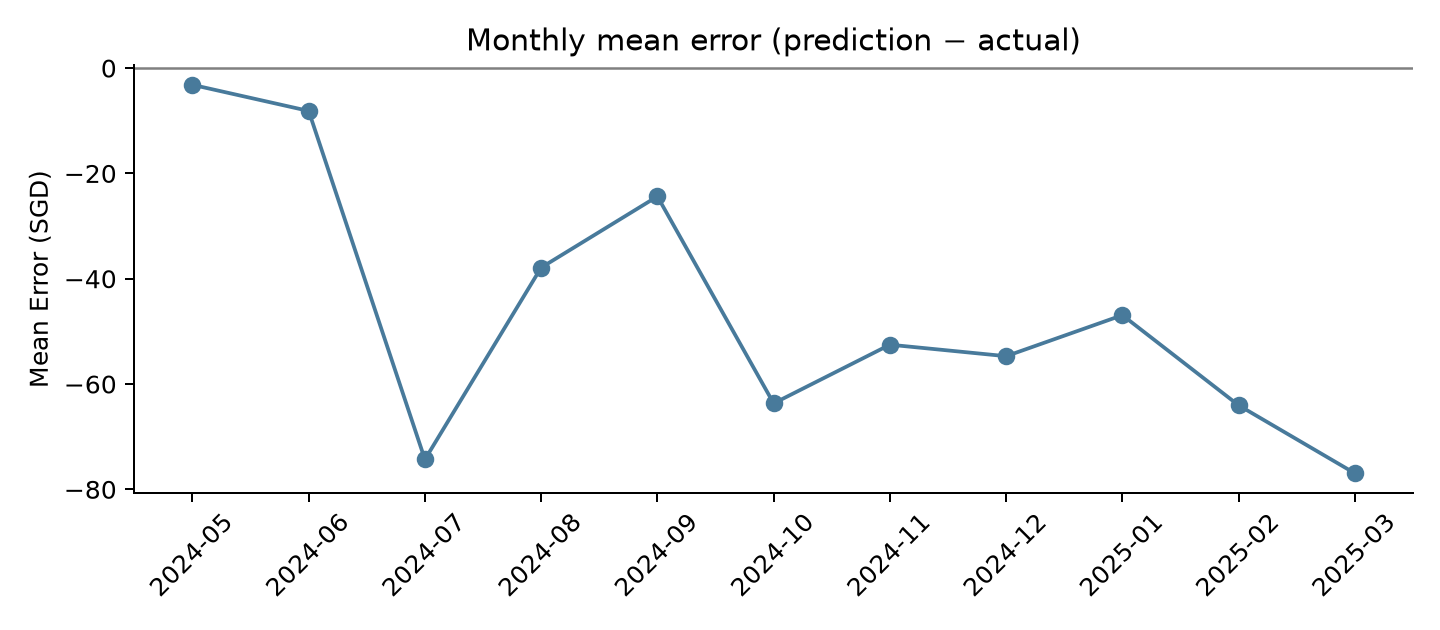

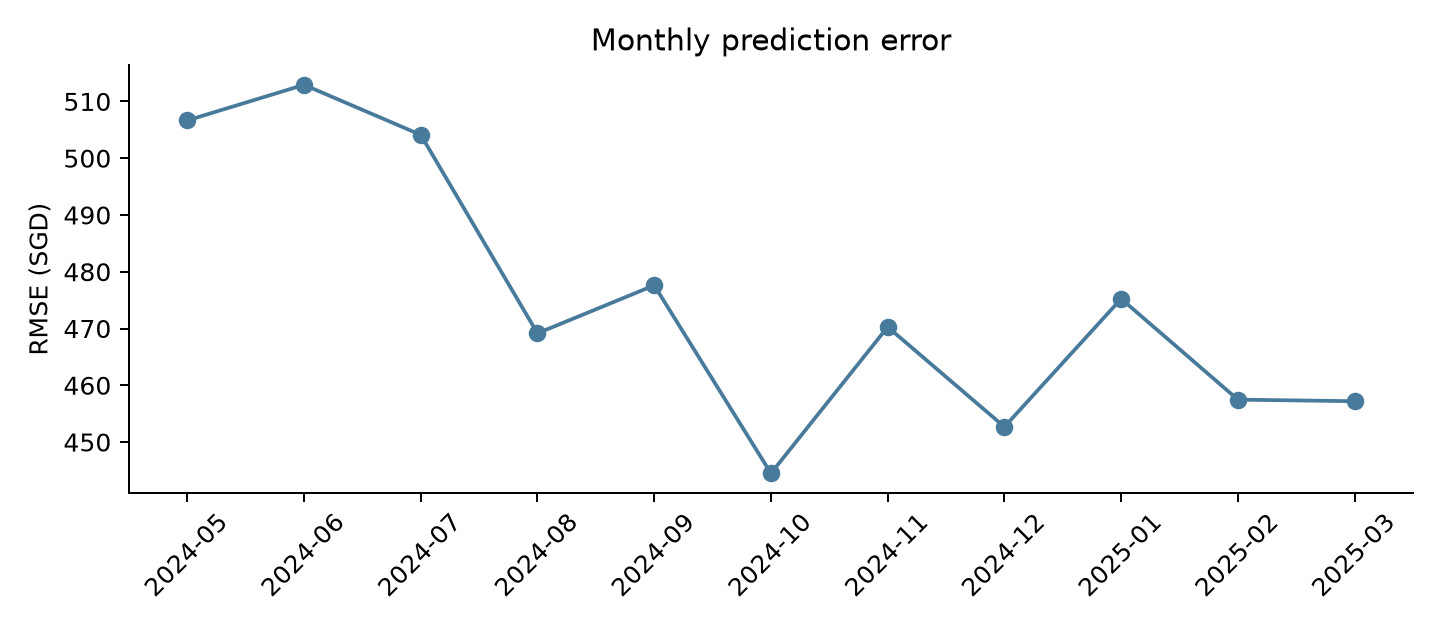

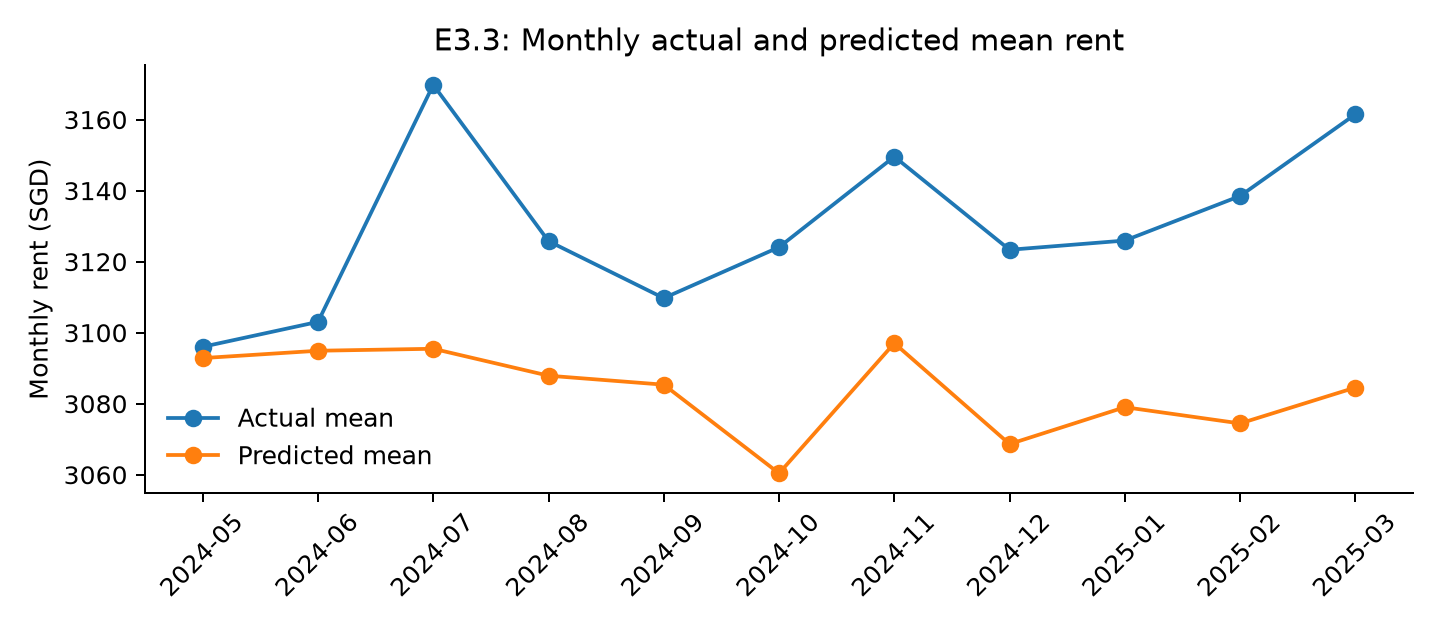

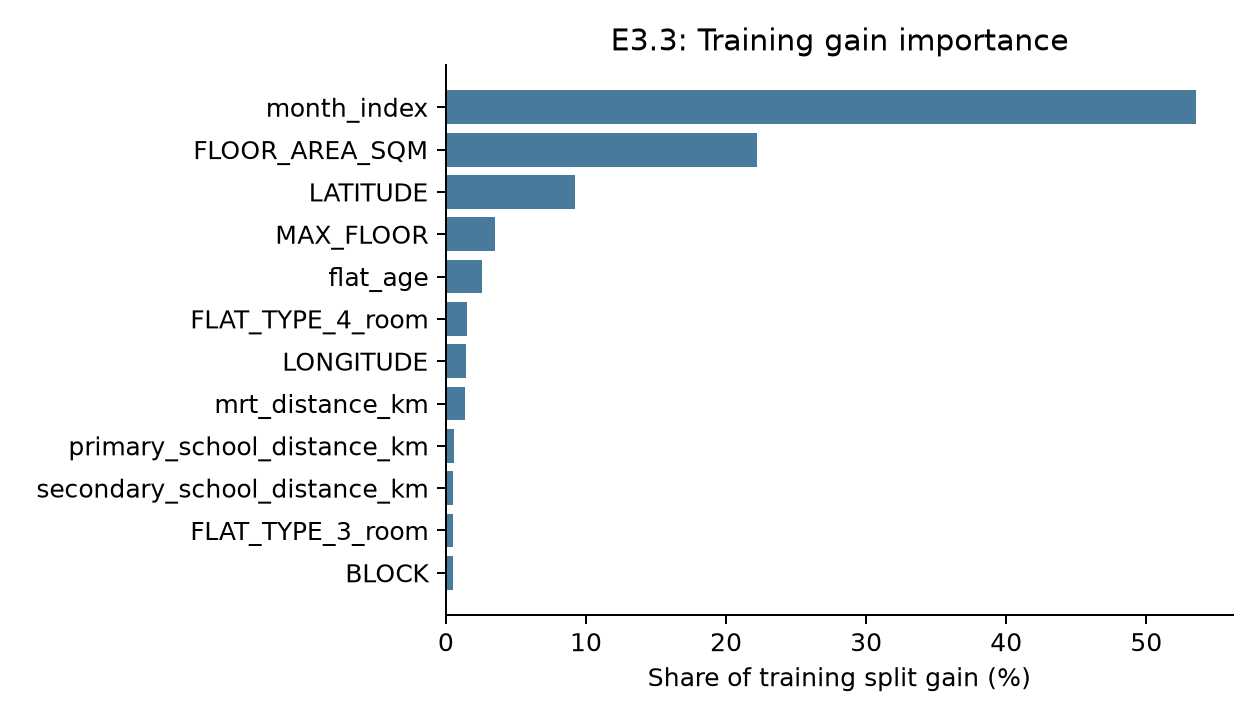

In [3]:
for file in ['monthly_mean_error.png','monthly_rmse.png','monthly_mean_rent.png','e33_gain_importance.png']:
    display(Image(filename=str(artifact(file))))